Desenvolvimento do projeto

Etapa 1 - Carregar a base de dados

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values="?",
    low_memory=False
)

print("Base carregada com sucesso!")

Base carregada com sucesso!


In [4]:
#Visualizar os cinco primeiros registros
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
#mostrar as últimas 5 linhas do DataFrame
df.tail()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075254,26/11/2010,20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2075255,26/11/2010,20:59:00,0.944,0.0,240.00,4.0,0.0,0.0,0.0
2075256,26/11/2010,21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2075257,26/11/2010,21:01:00,0.934,0.0,239.70,3.8,0.0,0.0,0.0
2075258,26/11/2010,21:02:00,0.932,0.0,239.55,3.8,0.0,0.0,0.0


In [6]:
print("Dimensões da base:", df.shape)

Dimensões da base: (2075259, 9)


Significa que temos 2.075.259 registros e 9 colunas

Antes de fazer o pré-processamento será feito o diagnóstico da base

In [7]:
#inspeção mais completa do DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [8]:
#saber o tipo de dado de cada coluna
df.dtypes

Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [9]:
#Faz o somatório dos valores nulo
df.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Mostra quantos valores ausentes existem por coluna

In [10]:
df.isnull().any(axis=1).sum()

25979

Mostra quantos registros possuem pelo menos um valor ausente

In [11]:
#informar ao Pandas quais valores do 
# arquivo devem ser considerados como 
# dados ausentes.
na_values="?"

In [12]:
#quantas linhas possuem algum valor ausente
df.isnull().any(axis=1).sum()

25979

In [13]:
#Verificar estatísticas dos atributos
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


Permitirá observar escala, média, desvio padrão, mínimo e máximo das variáveis

In [14]:
#Verificar os nomes das variáveis
df.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='object')

Isso é importante porque posteriormente teremos que decidir quais atributos serão utilizados no agrupamento.

In [15]:
#Verificar duplicidades
df.duplicated().sum()

0

In [16]:
#Quantidade de valores diferentes
df.nunique()

Date                     1442
Time                     1440
Global_active_power      4186
Global_reactive_power     532
Voltage                  2837
Global_intensity          221
Sub_metering_1             88
Sub_metering_2             81
Sub_metering_3             32
dtype: int64

Verificar as variáveis: Date, Time e Global_active_power

In [17]:
#Verificar as três colunas
print(df[["Date", "Time", "Global_active_power"]].head(10))

         Date      Time  Global_active_power
0  16/12/2006  17:24:00                4.216
1  16/12/2006  17:25:00                5.360
2  16/12/2006  17:26:00                5.374
3  16/12/2006  17:27:00                5.388
4  16/12/2006  17:28:00                3.666
5  16/12/2006  17:29:00                3.520
6  16/12/2006  17:30:00                3.702
7  16/12/2006  17:31:00                3.700
8  16/12/2006  17:32:00                3.668
9  16/12/2006  17:33:00                3.662


In [18]:
#descobrir se, por exemplo, Global_active_power está como object em vez de numérico
print(df[["Date", "Time", "Global_active_power"]].dtypes)

Date                    object
Time                    object
Global_active_power    float64
dtype: object


In [19]:
#Verificar como estão as datas
print(df["Date"].head(10))
print(df["Date"].unique()[:10])

0    16/12/2006
1    16/12/2006
2    16/12/2006
3    16/12/2006
4    16/12/2006
5    16/12/2006
6    16/12/2006
7    16/12/2006
8    16/12/2006
9    16/12/2006
Name: Date, dtype: object
['16/12/2006' '17/12/2006' '18/12/2006' '19/12/2006' '20/12/2006'
 '21/12/2006' '22/12/2006' '23/12/2006' '24/12/2006' '25/12/2006']


In [20]:
#verificar o número de dias
print("Quantidade de datas:", df["Date"].nunique())

Quantidade de datas: 1442


In [21]:
#Verificar como estão os horários
print(df["Time"].head(20))

0     17:24:00
1     17:25:00
2     17:26:00
3     17:27:00
4     17:28:00
5     17:29:00
6     17:30:00
7     17:31:00
8     17:32:00
9     17:33:00
10    17:34:00
11    17:35:00
12    17:36:00
13    17:37:00
14    17:38:00
15    17:39:00
16    17:40:00
17    17:41:00
18    17:42:00
19    17:43:00
Name: Time, dtype: object


In [22]:
print("Quantidade de horários diferentes:", df["Time"].nunique())

Quantidade de horários diferentes: 1440


In [23]:
#Para saber quais são os primeiros horários em ordem
print(sorted(df["Time"].dropna().unique())[:20])

['00:00:00', '00:01:00', '00:02:00', '00:03:00', '00:04:00', '00:05:00', '00:06:00', '00:07:00', '00:08:00', '00:09:00', '00:10:00', '00:11:00', '00:12:00', '00:13:00', '00:14:00', '00:15:00', '00:16:00', '00:17:00', '00:18:00', '00:19:00']


In [24]:
#Confirmar o intervalo entre as medições
data_hora = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

print(data_hora.head(10))

0   2006-12-16 17:24:00
1   2006-12-16 17:25:00
2   2006-12-16 17:26:00
3   2006-12-16 17:27:00
4   2006-12-16 17:28:00
5   2006-12-16 17:29:00
6   2006-12-16 17:30:00
7   2006-12-16 17:31:00
8   2006-12-16 17:32:00
9   2006-12-16 17:33:00
dtype: datetime64[ns]


In [25]:
#calcular a diferença entre uma medição e a anterior
intervalos = data_hora.diff()

print(intervalos.value_counts().head(10))

0 days 00:01:00    2075258
Name: count, dtype: int64


In [26]:
print("=== COLUNAS ===")
print(df[["Date", "Time", "Global_active_power"]].head())

print("\n=== TIPOS ===")
print(df[["Date", "Time", "Global_active_power"]].dtypes)

print("\n=== DATAS ===")
print("Quantidade de dias:", df["Date"].nunique())
print(df["Date"].head())

print("\n=== HORÁRIOS ===")
print("Quantidade de horários:", df["Time"].nunique())
print(df["Time"].head(10))

print("\n=== INTERVALO ENTRE MEDIÇÕES ===")

data_hora = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

=== COLUNAS ===
         Date      Time  Global_active_power
0  16/12/2006  17:24:00                4.216
1  16/12/2006  17:25:00                5.360
2  16/12/2006  17:26:00                5.374
3  16/12/2006  17:27:00                5.388
4  16/12/2006  17:28:00                3.666

=== TIPOS ===
Date                    object
Time                    object
Global_active_power    float64
dtype: object

=== DATAS ===
Quantidade de dias: 1442
0    16/12/2006
1    16/12/2006
2    16/12/2006
3    16/12/2006
4    16/12/2006
Name: Date, dtype: object

=== HORÁRIOS ===
Quantidade de horários: 1440
0    17:24:00
1    17:25:00
2    17:26:00
3    17:27:00
4    17:28:00
5    17:29:00
6    17:30:00
7    17:31:00
8    17:32:00
9    17:33:00
Name: Time, dtype: object

=== INTERVALO ENTRE MEDIÇÕES ===


In [27]:
print(intervalos.value_counts().head(5))

0 days 00:01:00    2075258
Name: count, dtype: int64


In [28]:
print("Valores ausentes:")
print(df[["Date", "Time", "Global_active_power"]].isnull().sum())

Valores ausentes:
Date                       0
Time                       0
Global_active_power    25979
dtype: int64


In [29]:
#Valores ausentes por dia
medicoes_por_dia = df.groupby("Date")["Global_active_power"].agg(
    total="count",
    ausentes=lambda x: x.isna().sum()
)

print(medicoes_por_dia.head())

           total  ausentes
Date                      
1/1/2007    1440         0
1/1/2008    1440         0
1/1/2009    1440         0
1/1/2010    1440         0
1/10/2007   1440         0


In [30]:
#quantos dias possuem algum valor ausente
dias_com_ausentes = (medicoes_por_dia["ausentes"] > 0).sum()

print("Dias com valores ausentes:", dias_com_ausentes)

Dias com valores ausentes: 82


In [31]:
#verificar a situação mais crítica
print(medicoes_por_dia["ausentes"].describe())

count    1442.000000
mean       18.015950
std       149.424491
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1440.000000
Name: ausentes, dtype: float64


Medir a distribuição dos valores ausentes por dia

In [32]:
# Agrupar os registros por data
diagnostico_dias = df.groupby("Date")["Global_active_power"].agg(
    total_registros="size",
    valores_validos="count",
    valores_ausentes=lambda x: x.isna().sum()
)

# Calcular o percentual de valores ausentes
diagnostico_dias["percentual_ausentes"] = (
    diagnostico_dias["valores_ausentes"] /
    diagnostico_dias["total_registros"]
) * 100

print(diagnostico_dias.head(10))

           total_registros  valores_validos  valores_ausentes  \
Date                                                            
1/1/2007              1440             1440                 0   
1/1/2008              1440             1440                 0   
1/1/2009              1440             1440                 0   
1/1/2010              1440             1440                 0   
1/10/2007             1440             1440                 0   
1/10/2008             1440             1440                 0   
1/10/2009             1440             1440                 0   
1/10/2010             1440             1440                 0   
1/11/2007             1440             1440                 0   
1/11/2008             1440             1440                 0   

           percentual_ausentes  
Date                            
1/1/2007                   0.0  
1/1/2008                   0.0  
1/1/2009                   0.0  
1/1/2010                   0.0  
1/10/2007            

Descobrir quantos dias foram afetados

In [33]:
dias_afetados = (
    diagnostico_dias["valores_ausentes"] > 0
).sum()

dias_completos = (
    diagnostico_dias["valores_ausentes"] == 0
).sum()

print("Dias com valores ausentes:", dias_afetados)
print("Dias sem valores ausentes:", dias_completos)

print("\nEstatísticas dos valores ausentes:")
print(diagnostico_dias["valores_ausentes"].describe())

Dias com valores ausentes: 82
Dias sem valores ausentes: 1360

Estatísticas dos valores ausentes:
count    1442.000000
mean       18.015950
std       149.424491
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1440.000000
Name: valores_ausentes, dtype: float64


Dias mais afetados

In [34]:
print(
    diagnostico_dias.sort_values(
        "percentual_ausentes",
        ascending=False
    ).head(10)
)

           total_registros  valores_validos  valores_ausentes  \
Date                                                            
27/9/2010             1440                0              1440   
18/8/2010             1440                0              1440   
20/8/2010             1440                0              1440   
14/6/2009             1440                0              1440   
19/8/2010             1440                0              1440   
21/8/2010             1440                0              1440   
26/9/2010             1440                0              1440   
13/1/2010             1440                0              1440   
29/4/2007             1440                0              1440   
28/4/2007             1440               21              1419   

           percentual_ausentes  
Date                            
27/9/2010           100.000000  
18/8/2010           100.000000  
20/8/2010           100.000000  
14/6/2009           100.000000  
19/8/2010           1

Visualizar a distribuição

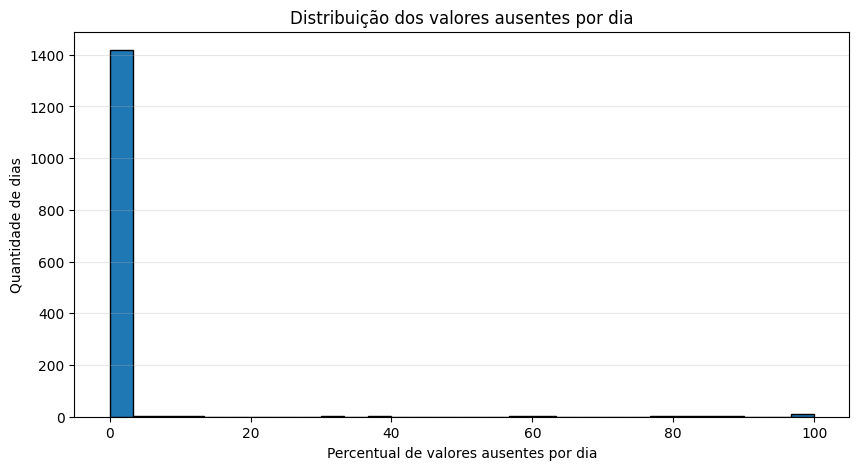

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    diagnostico_dias["percentual_ausentes"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Percentual de valores ausentes por dia")
plt.ylabel("Quantidade de dias")
plt.title("Distribuição dos valores ausentes por dia")

plt.grid(axis="y", alpha=0.3)
plt.show()

Verificar a distribuição por hora
Essa verificação é especialmente importante porque representa cada dia por 24 médias horárias.
Um dia pode ter apenas 5% de valores ausentes, mas esses valores podem estar concentrados em uma única hora. Nesse caso, o perfil horário pode ficar incompleto.

In [36]:
# Criar uma cópia para diagnóstico
df_diagnostico = df.copy()

# Converter data e hora
df_diagnostico["DataHora"] = pd.to_datetime(
    df_diagnostico["Date"] + " " + df_diagnostico["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

# Extrair data e hora
df_diagnostico["Dia"] = df_diagnostico["DataHora"].dt.date
df_diagnostico["Hora"] = df_diagnostico["DataHora"].dt.hour

# Contar ausências por dia e hora
ausentes_por_hora = (
    df_diagnostico
    .groupby(["Dia", "Hora"])["Global_active_power"]
    .apply(lambda x: x.isna().sum())
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

print(ausentes_por_hora.head())

Hora        0   1   2   3   4   5   6   7   8   9   ...  14  15  16  17  18  \
Dia                                                 ...                       
2006-12-16   0   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   0   
2006-12-17   0   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   0   
2006-12-18   0   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   0   
2006-12-19   0   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   0   
2006-12-20   0   0   0   0   0   0   0   0   0   0  ...   0   0   0   0   0   

Hora        19  20  21  22  23  
Dia                             
2006-12-16   0   0   0   0   0  
2006-12-17   0   0   0   0   0  
2006-12-18   0   0   0   0   0  
2006-12-19   0   0   0   0   0  
2006-12-20   0   0   0   0   0  

[5 rows x 24 columns]


O resultado terá 24 colunas, representando as horas de 0 a 23. Cada valor indicará quantas medições de consumo estão ausentes naquela hora.